In [27]:
from pathlib import Path
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (
  SparkSession.builder
  .appName("Phase2")
  .config("spark.driver.memory", "8g")
  .config("spark.executor.memory", "8g")
  .config("spark.sql.debug.maxToStringFields", "100")
  .getOrCreate()
)

review_df = spark.read.parquet("/home/cs179g/repo/data/labeled_reviews.parquet")
row_count = review_df.count()
print("Number of rows: " + str(row_count))

Number of rows: 1787844


In [28]:
review_df.show(5)

+--------+----------------+-----------+------------------+----------------+------------------+-----------------------+-----------------+--------+-------------+--------------+-----------------+--------+--------------------+--------+--------+-----------+-------------------+---------------------------+-----------------+-----------------+------------+-------------------+--------+----+----------+---------+--------------------+--------------+--------------------+-------------------+----------+--------------------+
|topic_id|recommendationid|last_played|author_num_reviews|playtime_forever|playtime_at_review|playtime_last_two_weeks|          steamid|language|comment_count|steam_purchase|received_for_free|refunded|              review|voted_up|votes_up|votes_funny|weighted_vote_score|written_during_early_access|timestamp_created|timestamp_updated|has_hardware|adapter_description|cpu_name|  os|system_ram|vram_size|          clean_text|raw_word_count|post_review_playtime|timestamp_formatted|topic

In [29]:
diff_df = review_df.filter(review_df.timestamp_created != review_df.timestamp_updated)
row_count = diff_df.count()
print("Number of rows: " + str(row_count))

Number of rows: 309477


In [30]:
import matplotlib.pyplot as plt
diff_df = diff_df.withColumn('rel_time', diff_df.timestamp_updated - 1344729600 )
diff_pd = diff_df.toPandas()
review_df = review_df.withColumn('rel_time', diff_df.timestamp_updated - 1344729600 )
review_pd = review_df.toPandas()

<Axes: ylabel='Frequency'>

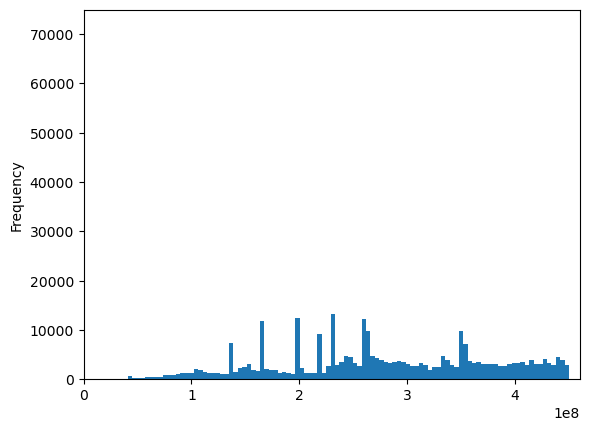

In [31]:
diff_pd.rel_time.plot.hist(bins=100, ylim=(0,75000), xlim=(0,460000000))

<Axes: xlabel='Time of updated review (unix time relative to start)', ylabel='Frequency'>

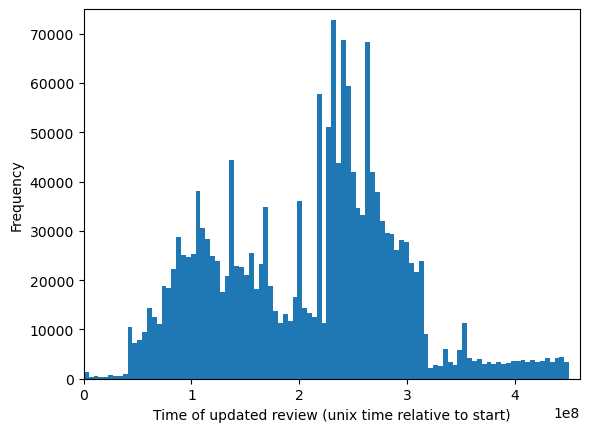

In [32]:
review_pd.rel_time.plot.hist(bins=100, ylim=(0,75000), xlim=(0,460000000), xlabel=('Time of updated review (unix time relative to start)'))